# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** [Michal Rivaldo Fresca Kurniawan]
- **Email:** [celeh0704@gmail.com]
- **ID Dicoding:** [michal_rivaldo_f5ue6]

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

**Konteks:** Dataset Bike Sharing berisi log penyewaan sepeda sistem Capital Bikeshare (Washington D.C., AS) selama dua tahun (2011-2012), dalam dua granularitas: harian (`day.csv`, 731 hari) dan per jam (`hour.csv`, 17.379 jam). Peran kita adalah analis data bagi tim operasional dan pemasaran penyedia layanan bike sharing.

- **Pertanyaan 1:** Pada jam berapa rata-rata penyewaan sepeda per jam mencapai puncak pada hari kerja dibandingkan akhir pekan/hari libur sepanjang tahun 2011-2012, dan berapa selisih rata-ratanya pada jam puncak tersebut, sebagai dasar penentuan jadwal redistribusi sepeda dan jendela perawatan armada?
- **Pertanyaan 2:** Musim dan kondisi cuaca (cerah, berkabut/berawan, hujan/salju ringan) apa yang memiliki rata-rata penyewaan sepeda harian tertinggi dan terendah sepanjang tahun 2011-2012, serta berapa persen pertumbuhan rata-rata penyewaan harian tahun 2012 dibandingkan 2011, sebagai dasar penentuan musim target promosi dan jadwal perawatan armada?

**Pemeriksaan SMART:**

| Elemen | Pertanyaan 1 | Pertanyaan 2 |
|---|---|---|
| Specific | Fokus pada jam puncak (0-23) penyewaan, hari kerja vs akhir pekan/hari libur | Fokus pada musim dan kondisi cuaca dengan rata-rata penyewaan harian tertinggi/terendah |
| Measurable | Rata-rata penyewaan per jam dan selisih rata-ratanya pada jam puncak | Rata-rata penyewaan harian per musim/cuaca dan persentase pertumbuhan 2012 vs 2011 |
| Action-Oriented | Dasar penentuan jadwal redistribusi sepeda dan jendela perawatan armada | Dasar penentuan musim target promosi dan jadwal perawatan armada |
| Relevant | Ketersediaan sepeda pada jam sibuk menentukan pendapatan dan kepuasan pengguna | Fluktuasi musiman memengaruhi pendapatan dan perencanaan armada |
| Time-bound | Sepanjang tahun 2011-2012 | Sepanjang tahun 2011-2012 (pertumbuhan 2012 dibandingkan 2011) |

## Import Semua Packages/Library yang Digunakan

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
%matplotlib inline

## Data Wrangling

### Gathering Data

Dataset dibagi ke dalam dua berkas dengan kolom yang sama (kecuali `hr` yang hanya ada di data per jam). Keduanya dimuat karena dibutuhkan untuk menjawab pertanyaan yang berbeda: data **per jam** untuk Pertanyaan 1 dan data **harian** untuk Pertanyaan 2.

Keterangan kolom utama: `season` (1: Spring, 2: Summer, 3: Fall, 4: Winter), `yr` (0: 2011, 1: 2012), `weathersit` (1: cerah/sedikit berawan, 2: berkabut/berawan, 3: hujan/salju ringan, 4: hujan lebat/salju + kabut), `temp`, `atemp`, `hum`, `windspeed` (ternormalisasi), serta `casual`, `registered`, dan `cnt` (total penyewaan).

#### Load day_df (data harian)

In [2]:
day_df = pd.read_csv("data/day.csv")
day_df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


#### Load hour_df (data per jam)

In [3]:
hour_df = pd.read_csv("data/hour.csv")
hour_df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:**
- `day_df` berisi 731 baris (tepat 2 tahun, 2011-2012) dan `hour_df` berisi 17.379 baris dengan tambahan kolom `hr`.
- Kolom `cnt` adalah penjumlahan `casual` dan `registered`, sehingga dapat dipakai sebagai ukuran total penyewaan.
- Banyak kolom masih berupa kode angka (`season`, `yr`, `weathersit`, `weekday`) dan nilai cuaca masih ternormalisasi, sehingga perlu diterjemahkan pada tahap cleaning.

### Assessing Data

#### Memeriksa struktur, tipe data, missing value, dan duplikasi

In [4]:
for name, df in [("day_df", day_df), ("hour_df", hour_df)]:
    print(f"=== {name}: {df.shape[0]} baris, {df.shape[1]} kolom ===")
    print("Tipe data  :", df.dtypes.astype(str).to_dict())
    print("Missing    :", int(df.isna().sum().sum()))
    print("Duplikat   :", int(df.duplicated().sum()))
    print()

=== day_df: 731 baris, 16 kolom ===
Tipe data  : {'instant': 'int64', 'dteday': 'str', 'season': 'int64', 'yr': 'int64', 'mnth': 'int64', 'holiday': 'int64', 'weekday': 'int64', 'workingday': 'int64', 'weathersit': 'int64', 'temp': 'float64', 'atemp': 'float64', 'hum': 'float64', 'windspeed': 'float64', 'casual': 'int64', 'registered': 'int64', 'cnt': 'int64'}
Missing    : 0
Duplikat   : 0

=== hour_df: 17379 baris, 17 kolom ===
Tipe data  : {'instant': 'int64', 'dteday': 'str', 'season': 'int64', 'yr': 'int64', 'mnth': 'int64', 'hr': 'int64', 'holiday': 'int64', 'weekday': 'int64', 'workingday': 'int64', 'weathersit': 'int64', 'temp': 'float64', 'atemp': 'float64', 'hum': 'float64', 'windspeed': 'float64', 'casual': 'int64', 'registered': 'int64', 'cnt': 'int64'}
Missing    : 0
Duplikat   : 0



#### Memeriksa nilai tidak valid dan tidak akurat

In [ ]:

print("cnt = casual + registered (day) :", (day_df["casual"] + day_df["registered"] == day_df["cnt"]).all())
print("cnt = casual + registered (hour):", (hour_df["casual"] + hour_df["registered"] == hour_df["cnt"]).all())

print("\nhum = 0 pada day_df :", (day_df["hum"] == 0).sum(), "baris ->", day_df.loc[day_df["hum"] == 0, "dteday"].tolist())
print("hum = 0 pada hour_df:", (hour_df["hum"] == 0).sum(), "baris")

print("\nwindspeed = 0 pada day_df :", (day_df["windspeed"] == 0).sum(), "baris")
print("windspeed = 0 pada hour_df:", (hour_df["windspeed"] == 0).sum(), "baris",
      f"({(hour_df['windspeed'] == 0).mean():.1%})")

print("\nDistribusi weathersit (day) :", day_df["weathersit"].value_counts().sort_index().to_dict())
print("Distribusi weathersit (hour):", hour_df["weathersit"].value_counts().sort_index().to_dict())

expected = pd.date_range("2011-01-01 00:00", "2012-12-31 23:00", freq="h")
print("\nJam yang seharusnya ada :", len(expected))
print("Jam pada hour_df        :", len(hour_df))
print("Jam yang hilang         :", len(expected) - len(hour_df))

cnt = casual + registered (day) : True
cnt = casual + registered (hour): True

hum = 0 pada day_df : 1 baris -> ['2011-03-10']
hum = 0 pada hour_df: 22 baris

windspeed = 0 pada day_df : 0 baris
windspeed = 0 pada hour_df: 2180 baris (12.5%)

Distribusi weathersit (day) : {1: 463, 2: 247, 3: 21}
Distribusi weathersit (hour): {1: 11413, 2: 4544, 3: 1419, 4: 3}

Jam yang seharusnya ada : 17544
Jam pada hour_df        : 17379
Jam yang hilang         : 165


#### Memeriksa outlier

In [6]:
def hitung_outlier(series):
    q1, q3 = series.quantile([0.25, 0.75])
    batas_atas = q3 + 1.5 * (q3 - q1)
    batas_bawah = q1 - 1.5 * (q3 - q1)
    return int(((series > batas_atas) | (series < batas_bawah)).sum())

print("Outlier hour_df (aturan IQR):")
for kolom in ["cnt", "casual", "registered", "windspeed"]:
    print(f"  {kolom:<11}: {hitung_outlier(hour_df[kolom])} baris")

print("\nOutlier day_df (aturan IQR):")
for kolom in ["cnt", "casual", "windspeed"]:
    print(f"  {kolom:<11}: {hitung_outlier(day_df[kolom])} baris")

print("\nHari dengan penyewaan terendah:")
day_df.nsmallest(3, "cnt")[["dteday", "cnt", "weathersit", "hum", "windspeed"]]

Outlier hour_df (aturan IQR):
  cnt        : 505 baris
  casual     : 1192 baris
  registered : 680 baris
  windspeed  : 342 baris

Outlier day_df (aturan IQR):
  cnt        : 0 baris
  casual     : 44 baris
  windspeed  : 13 baris

Hari dengan penyewaan terendah:


,dteday,cnt,weathersit,hum,windspeed
667,2012-10-29,22,3,0.880000,0.358200
26,2011-01-27,431,1,0.687500,0.113837
725,2012-12-26,441,3,0.823333,0.316546


**Steps to Take:**
- **Tipe data tidak sesuai:** `dteday` masih bertipe teks, ubah ke `datetime`.
- **Nilai kategorikal berupa kode (inconsistent/tidak informatif):** `season`, `yr`, `weathersit`, `weekday` diterjemahkan ke label yang mudah dibaca, dan ditambahkan kolom `day_type` (Hari Kerja vs Akhir Pekan/Libur) dari `workingday`.
- **Nilai ternormalisasi (inaccurate untuk interpretasi):** `temp`, `atemp`, `hum`, `windspeed` dikembalikan ke skala aslinya (dikali 41, 50, 100, 67) sesuai keterangan dataset.
- **Invalid value:** `hum = 0` (1 hari pada `day_df`, 22 jam pada `hour_df`) tidak masuk akal secara fisik, ganti menjadi `NaN` lalu isi dengan interpolasi (`day_df`). `windspeed = 0` pada `hour_df` sangat sering muncul (sekitar 12,5%) sehingga lebih mirip pengukuran yang tidak tercatat, ganti menjadi `NaN` dan tidak diimputasi karena kolom ini tidak dipakai untuk menjawab pertanyaan.
- **Data tidak lengkap:** `hour_df` kehilangan 165 jam dari total 17.544 jam. Jam tersebut kemungkinan tidak ada transaksi/tidak tercatat, sehingga tidak diisi (rata-rata per jam dihitung dari jam yang tercatat) dan keterbatasan ini dicatat.
- **Outlier:** nilai `cnt` yang tinggi muncul pada jam sibuk dan nilai terendah (22 sewa pada 2012-10-29) bertepatan dengan cuaca ekstrem, sehingga merupakan nilai yang sah dan **dipertahankan**.

**Insight:**
- Tidak ada missing value maupun data duplikat pada kedua berkas, tetapi ditemukan beberapa masalah lain: tipe data tanggal, kode kategorikal, nilai ternormalisasi, nilai tidak valid (`hum = 0`, `windspeed = 0`), dan 165 jam yang tidak tercatat.
- Kategori cuaca 4 (hujan lebat/salju) hanya muncul 3 jam dan tidak ada di data harian, sehingga perbandingan cuaca akan fokus pada kategori 1-3.

### Cleaning Data

#### Fixing tipe data, label kategorikal, dan skala nilai

In [7]:
def bersihkan(df):
    df = df.copy()
    # Tipe data tanggal
    df["dteday"] = pd.to_datetime(df["dteday"])
    df = df.rename(columns={"hr": "hour"})

    # Terjemahkan kode kategorikal menjadi label
    df["season"] = df["season"].map({1: "Spring", 2: "Summer", 3: "Fall", 4: "Winter"})
    df["year"] = df["yr"].map({0: 2011, 1: 2012})
    df["weekday"] = df["weekday"].map({0: "Minggu", 1: "Senin", 2: "Selasa", 3: "Rabu",
                                       4: "Kamis", 5: "Jumat", 6: "Sabtu"})
    df["weather"] = df["weathersit"].map({
        1: "Cerah/Sedikit Berawan",
        2: "Berkabut/Berawan",
        3: "Hujan/Salju Ringan",
        4: "Hujan Lebat/Salju"})
    df["day_type"] = np.where(df["workingday"] == 1, "Hari Kerja", "Akhir Pekan/Libur")

    # Kembalikan nilai ternormalisasi ke skala aslinya
    df["temp_c"] = df["temp"] * 41
    df["atemp_c"] = df["atemp"] * 50
    df["hum_pct"] = df["hum"] * 100
    df["windspeed"] = df["windspeed"] * 67

    kolom_dibuang = ["instant", "yr", "weathersit", "temp", "atemp", "hum"]
    return df.drop(columns=kolom_dibuang)

day_df = bersihkan(day_df)
hour_df = bersihkan(hour_df)
day_df.head()

,dteday,season,mnth,holiday,weekday,workingday,windspeed,casual,registered,cnt,year,weather,day_type,temp_c,atemp_c,hum_pct
0,2011-01-01,Spring,1,0,Sabtu,0,10.749882,331,654,985,2011,Berkabut/Berawan,Akhir Pekan/Libur,14.110847,18.18125,80.5833
1,2011-01-02,Spring,1,0,Minggu,0,16.652113,131,670,801,2011,Berkabut/Berawan,Akhir Pekan/Libur,14.902598,17.68695,69.6087
2,2011-01-03,Spring,1,0,Senin,1,16.636703,120,1229,1349,2011,Cerah/Sedikit Berawan,Hari Kerja,8.050924,9.47025,43.7273
3,2011-01-04,Spring,1,0,Selasa,1,10.739832,108,1454,1562,2011,Cerah/Sedikit Berawan,Hari Kerja,8.200000,10.60610,59.0435
4,2011-01-05,Spring,1,0,Rabu,1,12.522300,82,1518,1600,2011,Cerah/Sedikit Berawan,Hari Kerja,9.305237,11.46350,43.6957


#### Fixing invalid value (kelembapan dan kecepatan angin bernilai 0)

In [ ]:

day_df.loc[day_df["hum_pct"] == 0, "hum_pct"] = np.nan
day_df["hum_pct"] = day_df["hum_pct"].interpolate()
hour_df.loc[hour_df["hum_pct"] == 0, "hum_pct"] = np.nan   

hour_df.loc[hour_df["windspeed"] == 0, "windspeed"] = np.nan

print("Sisa hum_pct NaN  (day) :", day_df["hum_pct"].isna().sum())
print("Sisa hum_pct NaN  (hour):", hour_df["hum_pct"].isna().sum())
print("Sisa windspeed NaN (hour):", hour_df["windspeed"].isna().sum())
print("\nRentang suhu (C):", day_df["temp_c"].min().round(1), "-", day_df["temp_c"].max().round(1))
print("Rentang kelembapan (%):", day_df["hum_pct"].min().round(1), "-", day_df["hum_pct"].max().round(1))

Sisa hum_pct NaN  (day) : 0
Sisa hum_pct NaN  (hour): 22
Sisa windspeed NaN (hour): 2180

Rentang suhu (C): 2.4 - 35.3
Rentang kelembapan (%): 18.8 - 97.2


#### Menyimpan data bersih untuk dashboard

In [9]:
day_df.to_csv("dashboard/day_data.csv", index=False)
hour_df.to_csv("dashboard/main_data.csv", index=False)
print("Tersimpan:", day_df.shape, hour_df.shape)

Tersimpan: (731, 16) (17379, 17)


**Insight:**
- Seluruh kolom kini memiliki tipe dan satuan yang sesuai (tanggal, label musim/cuaca, suhu dalam °C, kelembapan dalam %).
- Outlier pada `cnt` tidak dihapus karena mencerminkan perilaku nyata (jam sibuk dan cuaca ekstrem).
- Data bersih disimpan ke folder `dashboard/` agar dashboard Streamlit memakai data yang sama dengan notebook.

## Exploratory Data Analysis (EDA)

### Explore ringkasan statistik

In [10]:
day_df[["cnt", "casual", "registered", "temp_c", "hum_pct", "windspeed"]].describe().round(1)

,cnt,casual,registered,temp_c,hum_pct,windspeed
count,731.0,731.0,731.0,731.0,731.0,731.0
mean,4504.3,848.2,3656.2,20.3,62.9,12.8
std,1937.2,686.6,1560.3,7.5,14.1,5.2
min,22.0,2.0,20.0,2.4,18.8,1.5
25%,3152.0,315.5,2497.0,13.8,52.1,9.0
50%,4548.0,713.0,3662.0,20.4,62.7,12.1
75%,5956.0,1096.0,4776.5,26.9,73.0,15.6
max,8714.0,3410.0,6946.0,35.3,97.2,34.0


### Explore pola penyewaan per jam: hari kerja vs akhir pekan/libur (Pertanyaan 1)

In [11]:
hourly = hour_df.groupby(["day_type", "hour"])["cnt"].mean().unstack(0)

print("3 jam tersibuk (rata-rata sewa per jam):")
for tipe in hourly.columns:
    print(f"  {tipe:<18}:", {f"{h:02d}.00": round(v) for h, v in hourly[tipe].nlargest(3).items()})

print("\nPerbandingan jam-jam kunci (rata-rata sewa per jam):")
jam_kunci = hourly.loc[[3, 8, 13, 17]].round(0)
jam_kunci["Selisih (Kerja - Libur)"] = jam_kunci["Hari Kerja"] - jam_kunci["Akhir Pekan/Libur"]
jam_kunci

3 jam tersibuk (rata-rata sewa per jam):
  Akhir Pekan/Libur : {'13.00': 373, '12.00': 366, '14.00': 365}
  Hari Kerja        : {'17.00': 525, '18.00': 492, '08.00': 477}

Perbandingan jam-jam kunci (rata-rata sewa per jam):


day_type,Akhir Pekan/Libur,Hari Kerja,Selisih (Kerja - Libur)
hour,,,
3,26.0,5.0,-21.0
8,106.0,477.0,371.0
13,373.0,198.0,-175.0
17,324.0,525.0,201.0


In [12]:
kerja = hour_df[hour_df["day_type"] == "Hari Kerja"]
libur = hour_df[hour_df["day_type"] == "Akhir Pekan/Libur"]

porsi_rush = kerja[kerja["hour"].isin([7, 8, 9, 16, 17, 18, 19])]["cnt"].sum() / kerja["cnt"].sum()
porsi_siang_libur = libur[libur["hour"].between(11, 16)]["cnt"].sum() / libur["cnt"].sum()
porsi_sepi_kerja = kerja[kerja["hour"].between(0, 5)]["cnt"].sum() / kerja["cnt"].sum()

print(f"Porsi sewa jam sibuk (07-09 & 16-19) pada hari kerja : {porsi_rush:.1%}")
print(f"Porsi sewa pukul 11-16 pada akhir pekan/libur        : {porsi_siang_libur:.1%}")
print(f"Porsi sewa pukul 00-05 pada hari kerja               : {porsi_sepi_kerja:.1%}")

print("\nKomposisi pengguna (total sewa):")
(hour_df.groupby("day_type")[["casual", "registered"]].sum()
 .pipe(lambda x: x.div(x.sum(axis=1), axis=0)).round(3))

Porsi sewa jam sibuk (07-09 & 16-19) pada hari kerja : 57.9%
Porsi sewa pukul 11-16 pada akhir pekan/libur        : 49.2%
Porsi sewa pukul 00-05 pada hari kerja               : 2.1%

Komposisi pengguna (total sewa):


,casual,registered
day_type,,
Akhir Pekan/Libur,0.317,0.683
Hari Kerja,0.132,0.868


### Explore pengaruh musim, cuaca, dan tahun (Pertanyaan 2)

In [13]:
print("Rata-rata penyewaan harian per tahun:")
per_tahun = day_df.groupby("year")["cnt"].mean()
print(per_tahun.round(0).to_dict())
print(f"Pertumbuhan 2012 vs 2011: {per_tahun[2012] / per_tahun[2011] - 1:.1%}")

print("\nRata-rata penyewaan harian per musim x tahun:")
musim_tahun = day_df.pivot_table(index="season", columns="year", values="cnt", aggfunc="mean").loc[["Spring", "Summer", "Fall", "Winter"]]
musim_tahun["Pertumbuhan"] = (musim_tahun[2012] / musim_tahun[2011] - 1).map("{:.0%}".format)
display(musim_tahun.round(0))

print("Rata-rata penyewaan harian per musim (gabungan 2011-2012):")
print(day_df.groupby("season")["cnt"].mean().round(0).sort_values(ascending=False).to_dict())

Rata-rata penyewaan harian per tahun:
{2011: 3406.0, 2012: 5600.0}
Pertumbuhan 2012 vs 2011: 64.4%

Rata-rata penyewaan harian per musim x tahun:


year,2011,2012,Pertumbuhan
season,,,
Spring,1667.0,3531.0,112%
Summer,3775.0,6209.0,64%
Fall,4464.0,6824.0,53%
Winter,3664.0,5792.0,58%


Rata-rata penyewaan harian per musim (gabungan 2011-2012):
{'Fall': 5644.0, 'Summer': 4992.0, 'Winter': 4728.0, 'Spring': 2604.0}


In [14]:
cuaca = day_df.groupby("weather")["cnt"].agg(jumlah_hari="count", rata_rata="mean").round(0)
cuaca["selisih_vs_cerah"] = (cuaca["rata_rata"] / cuaca.loc["Cerah/Sedikit Berawan", "rata_rata"] - 1).map("{:.1%}".format)
display(cuaca.sort_values("rata_rata", ascending=False))

print("Korelasi suhu (temp_c) dengan total sewa harian :", round(day_df["temp_c"].corr(day_df["cnt"]), 2))
print("Korelasi kelembapan dengan total sewa harian   :", round(day_df["hum_pct"].corr(day_df["cnt"]), 2))
print("Korelasi kecepatan angin dengan total sewa harian:", round(day_df["windspeed"].corr(day_df["cnt"]), 2))

,jumlah_hari,rata_rata,selisih_vs_cerah
weather,,,
Cerah/Sedikit Berawan,463,4877.0,0.0%
Berkabut/Berawan,247,4036.0,-17.2%
Hujan/Salju Ringan,21,1803.0,-63.0%


Korelasi suhu (temp_c) dengan total sewa harian : 0.63
Korelasi kelembapan dengan total sewa harian   : -0.12
Korelasi kecepatan angin dengan total sewa harian: -0.23


**Insight:**
- **Pola jam (Pertanyaan 1):** hari kerja memiliki dua puncak tajam (pagi sekitar 08.00 dan sore sekitar 17.00-18.00) yang khas pola komuter, sedangkan akhir pekan/libur hanya memiliki satu puncak landai pada siang hari (sekitar 12.00-14.00). Pada 08.00 hari kerja rata-rata sewa sekitar 4,5 kali akhir pekan, sebaliknya pada 13.00 akhir pekan hampir dua kali hari kerja.
- **Musim (Pertanyaan 2):** Fall adalah musim tersibuk dan Spring yang terendah. Setiap musim naik cukup besar dari 2011 ke 2012, rata-rata penyewaan harian tumbuh sekitar 64%.
- **Cuaca:** semakin buruk cuaca, semakin rendah penyewaan; hari hujan/salju ringan turun sekitar 63% dibanding hari cerah, tetapi hanya 21 hari (sekitar 3%) sehingga hasilnya perlu dibaca hati-hati.
- Suhu berkorelasi positif cukup kuat dengan penyewaan harian (r ≈ 0,63), sedangkan kelembapan (r ≈ -0,12) dan kecepatan angin (r ≈ -0,23) berkorelasi negatif lemah.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Pada jam berapa rata-rata penyewaan sepeda per jam mencapai puncak pada hari kerja dibandingkan akhir pekan/hari libur sepanjang tahun 2011-2012, dan berapa selisih rata-ratanya pada jam puncak tersebut, sebagai dasar penentuan jadwal redistribusi sepeda dan jendela perawatan armada?

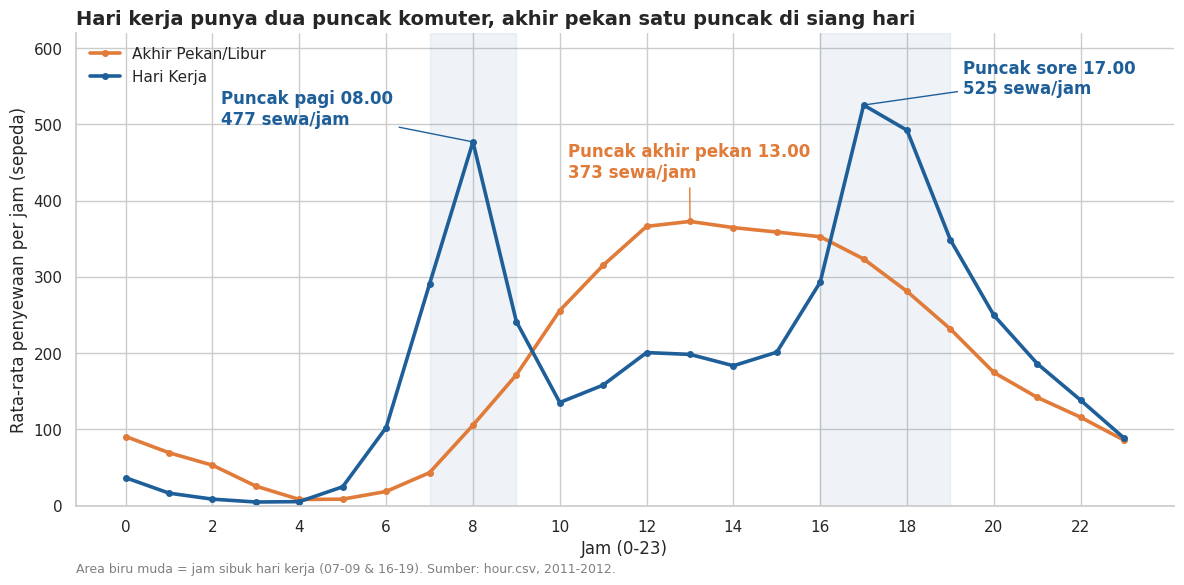

In [15]:
warna = {"Hari Kerja": "#1f5f99", "Akhir Pekan/Libur": "#e07b39"}

fig, ax = plt.subplots(figsize=(12, 6))
ax.axvspan(7, 9, color="#1f5f99", alpha=0.07)
ax.axvspan(16, 19, color="#1f5f99", alpha=0.07)

for tipe in hourly.columns:
    ax.plot(hourly.index, hourly[tipe], marker="o", markersize=4, linewidth=2.6,
            color=warna[tipe], label=tipe)

# Anotasi puncak
ax.annotate("Puncak sore 17.00\n525 sewa/jam", xy=(17, hourly.loc[17, "Hari Kerja"]),
            xytext=(19.3, 540), color=warna["Hari Kerja"], fontweight="bold",
            arrowprops=dict(arrowstyle="-", color=warna["Hari Kerja"]))
ax.annotate("Puncak pagi 08.00\n477 sewa/jam", xy=(8, hourly.loc[8, "Hari Kerja"]),
            xytext=(2.2, 500), color=warna["Hari Kerja"], fontweight="bold",
            arrowprops=dict(arrowstyle="-", color=warna["Hari Kerja"]))
ax.annotate("Puncak akhir pekan 13.00\n373 sewa/jam", xy=(13, hourly.loc[13, "Akhir Pekan/Libur"]),
            xytext=(10.2, 430), color=warna["Akhir Pekan/Libur"], fontweight="bold",
            arrowprops=dict(arrowstyle="-", color=warna["Akhir Pekan/Libur"]))

ax.set_title("Hari kerja punya dua puncak komuter, akhir pekan satu puncak di siang hari",
             fontsize=14, fontweight="bold", loc="left")
ax.set_xlabel("Jam (0-23)")
ax.set_ylabel("Rata-rata penyewaan per jam (sepeda)")
ax.set_xticks(range(0, 24, 2))
ax.set_ylim(0, 620)
ax.legend(frameon=False, loc="upper left")
ax.text(0, -0.14, "Area biru muda = jam sibuk hari kerja (07-09 & 16-19). Sumber: hour.csv, 2011-2012.",
        transform=ax.transAxes, fontsize=9, color="gray")
plt.tight_layout()
plt.show()

**Penjelasan grafik:** garis biru (hari kerja) dan oranye (akhir pekan/libur) menunjukkan rata-rata penyewaan pada setiap jam 0-23; area biru muda menandai jam sibuk hari kerja.

**Insight:**
- Pada hari kerja, penyewaan memuncak pukul **17.00 (±525/jam)**, lalu **18.00 (±492)** dan **08.00 (±477)**. Pukul 07-09 dan 16-19 menyumbang sekitar **58%** seluruh sewa hari kerja.
- Pada akhir pekan/libur, puncak ada pukul **13.00 (±373/jam)** dan penyewaan terkonsentrasi pukul 11-16 (sekitar **49%** dari total sewa).
- Selisih terbesar ada pada jam komuter pagi (08.00: ±477 vs ±106) dan jam tengah hari (13.00: ±198 vs ±373, akhir pekan lebih tinggi).

### Pertanyaan 2: Musim dan kondisi cuaca (cerah, berkabut/berawan, hujan/salju ringan) apa yang memiliki rata-rata penyewaan sepeda harian tertinggi dan terendah sepanjang tahun 2011-2012, serta berapa persen pertumbuhan rata-rata penyewaan harian tahun 2012 dibandingkan 2011, sebagai dasar penentuan musim target promosi dan jadwal perawatan armada?

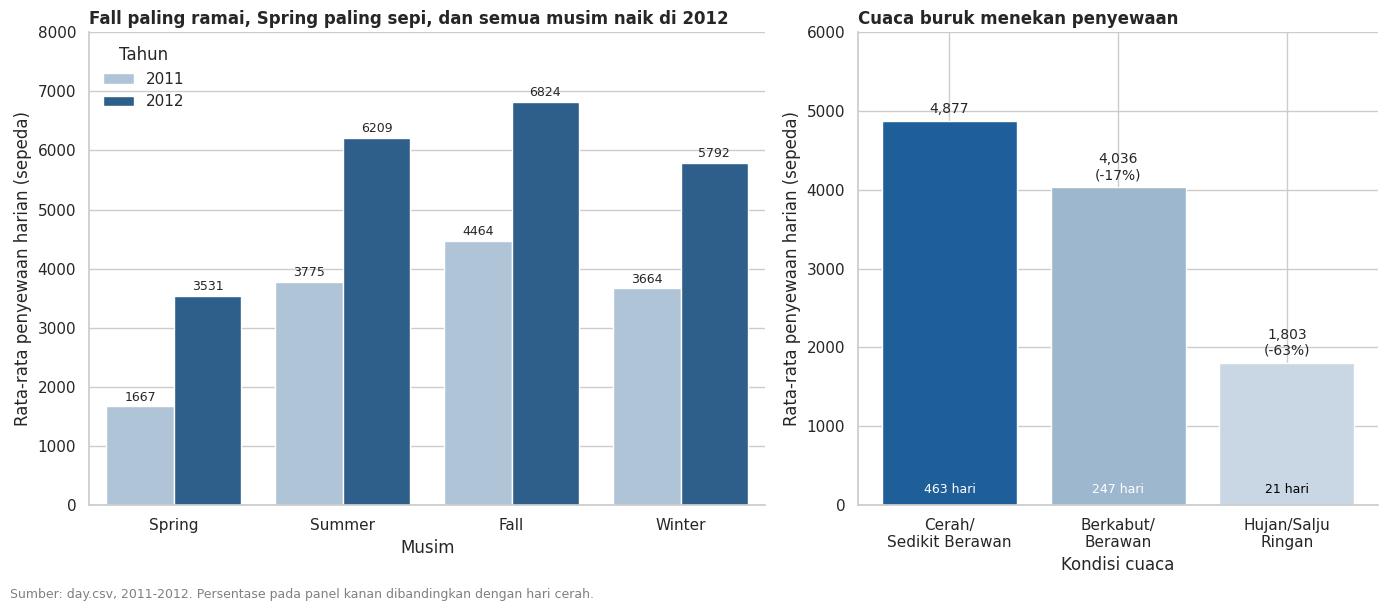

In [ ]:
urutan_musim = ["Spring", "Summer", "Fall", "Winter"]
fig, axes = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={"width_ratios": [1.3, 1]})

sns.barplot(data=day_df, x="season", y="cnt", hue="year", order=urutan_musim,
            errorbar=None, palette={2011: "#a9c4de", 2012: "#1f5f99"}, ax=axes[0])
for wadah in axes[0].containers:
    axes[0].bar_label(wadah, fmt="%.0f", padding=2, fontsize=9)
axes[0].set_title("Fall paling ramai, Spring paling sepi, dan semua musim naik di 2012",
                  fontsize=12, fontweight="bold", loc="left")
axes[0].set_xlabel("Musim")
axes[0].set_ylabel("Rata-rata penyewaan harian (sepeda)")
axes[0].legend(title="Tahun", frameon=False, loc="upper left")
axes[0].set_ylim(0, 8000)

urutan_cuaca = ["Cerah/Sedikit Berawan", "Berkabut/Berawan", "Hujan/Salju Ringan"]
rata_cuaca = day_df.groupby("weather")["cnt"].mean().loc[urutan_cuaca]
jumlah_hari = day_df["weather"].value_counts().loc[urutan_cuaca]
warna_cuaca = ["#1f5f99", "#9db7cf", "#c9d6e3"]
batang = axes[1].bar(["Cerah/\nSedikit Berawan", "Berkabut/\nBerawan", "Hujan/Salju\nRingan"],
                     rata_cuaca.values, color=warna_cuaca)
for b, nilai, n in zip(batang, rata_cuaca.values, jumlah_hari.values):
    selisih = nilai / rata_cuaca.iloc[0] - 1
    label = f"{nilai:,.0f}" if selisih == 0 else f"{nilai:,.0f}\n({selisih:+.0%})"
    axes[1].text(b.get_x() + b.get_width() / 2, nilai + 100, label, ha="center", fontsize=10)
    axes[1].text(b.get_x() + b.get_width() / 2, 150, f"{n} hari", ha="center", fontsize=9,
                 color="white" if nilai > 3000 else "black")
axes[1].set_title("Cuaca buruk menekan penyewaan", fontsize=12, fontweight="bold", loc="left")
axes[1].set_xlabel("Kondisi cuaca")
axes[1].set_ylabel("Rata-rata penyewaan harian (sepeda)")
axes[1].set_ylim(0, 6000)

fig.text(0.01, -0.01, "Sumber: day.csv, 2011-2012. Persentase pada panel kanan dibandingkan dengan hari cerah.",
         fontsize=9, color="gray")
plt.tight_layout()
plt.show()

**Penjelasan grafik:** panel kiri membandingkan rata-rata penyewaan harian tiap musim pada 2011 dan 2012; panel kanan membandingkan rata-rata penyewaan harian menurut kondisi cuaca (jumlah hari tertera di dalam batang).

**Insight:**
- Rata-rata penyewaan harian tertinggi ada pada **Fall (±5.644)**, diikuti Summer (±4.992), Winter (±4.728), dan terendah **Spring (±2.604)**.
- Seluruh musim naik dari 2011 ke 2012; rata-rata harian tumbuh **±64%** (±3.406 menjadi ±5.600). Pertumbuhan terbesar terjadi pada Spring (±112%).
- Dibanding hari cerah (±4.877), hari berkabut/berawan memiliki rata-rata **±17%** lebih rendah (±4.036) dan hari hujan/salju ringan turun **±63%** (±1.803, hanya 21 hari).

## Analisis Lanjutan (Opsional)

Analisis lanjutan memakai teknik **Manual Grouping dan Binning** (tanpa algoritma machine learning). Tujuannya mengelompokkan data berdasarkan aturan bisnis agar tim bisa menyusun tindakan yang lebih praktis:
1. **Segmen waktu** (manual grouping jam): Dini Hari, Pagi (Jam Sibuk), Siang, Sore (Jam Sibuk), Malam, untuk melihat pola kebutuhan sepeda dan komposisi pengguna per segmen.
2. **Binning suhu**: Dingin (<10°C), Sejuk (10-20°C), Hangat (20-30°C), Panas (>30°C), untuk melihat kisaran suhu yang paling ramai.
3. **Binning tingkat permintaan harian** berdasarkan kuartil `cnt` (Rendah, Sedang, Tinggi, Sangat Tinggi), untuk melihat musim mana yang paling banyak mengalami hari permintaan tinggi.

In [ ]:

def segmen_waktu(jam):
    if jam <= 5:
        return "1. Dini Hari (00-05)"
    elif jam <= 9:
        return "2. Pagi (06-09)"
    elif jam <= 15:
        return "3. Siang (10-15)"
    elif jam <= 19:
        return "4. Sore (16-19)"
    return "5. Malam (20-23)"

hour_df["time_segment"] = hour_df["hour"].apply(segmen_waktu)

segmen = (hour_df.groupby(["time_segment", "day_type"])["cnt"].mean().unstack().round(0))
porsi_casual = (hour_df.groupby("time_segment")[["casual", "registered"]].sum()
                .pipe(lambda x: (x["casual"] / (x["casual"] + x["registered"])).round(3)))
segmen["Porsi pengguna casual"] = porsi_casual.map("{:.0%}".format)
segmen

day_type,Akhir Pekan/Libur,Hari Kerja,Porsi pengguna casual
time_segment,,,
1. Dini Hari (00-05),43.0,16.0,18%
2. Pagi (06-09),85.0,278.0,8%
3. Siang (10-15),339.0,180.0,29%
4. Sore (16-19),297.0,415.0,17%
5. Malam (20-23),130.0,166.0,16%


In [ ]:

day_df["temp_group"] = pd.cut(day_df["temp_c"], bins=[-np.inf, 10, 20, 30, np.inf],
                              labels=["Dingin (<10°C)", "Sejuk (10-20°C)", "Hangat (20-30°C)", "Panas (>30°C)"])
suhu = day_df.groupby("temp_group", observed=True)["cnt"].agg(jumlah_hari="count", rata_rata="mean").round(0)
suhu

,jumlah_hari,rata_rata
temp_group,,
Dingin (<10°C),60,1678.0
Sejuk (10-20°C),299,3692.0
Hangat (20-30°C),300,5662.0
Panas (>30°C),72,5410.0


In [ ]:

day_df["demand_level"] = pd.qcut(day_df["cnt"], q=4, labels=["Rendah", "Sedang", "Tinggi", "Sangat Tinggi"])
print("Batas kuartil cnt:", day_df["cnt"].quantile([0.25, 0.5, 0.75]).round(0).to_dict())

permintaan = (pd.crosstab(day_df["season"], day_df["demand_level"], normalize="index")
              .loc[["Spring", "Summer", "Fall", "Winter"]])
permintaan = (permintaan * 100).round(0).astype(int).astype(str) + "%"
permintaan

Batas kuartil cnt: {0.25: 3152.0, 0.5: 4548.0, 0.75: 5956.0}


demand_level,Rendah,Sedang,Tinggi,Sangat Tinggi
season,,,,
Spring,67%,24%,6%,3%
Summer,15%,23%,28%,34%
Fall,2%,22%,34%,42%
Winter,16%,31%,31%,21%


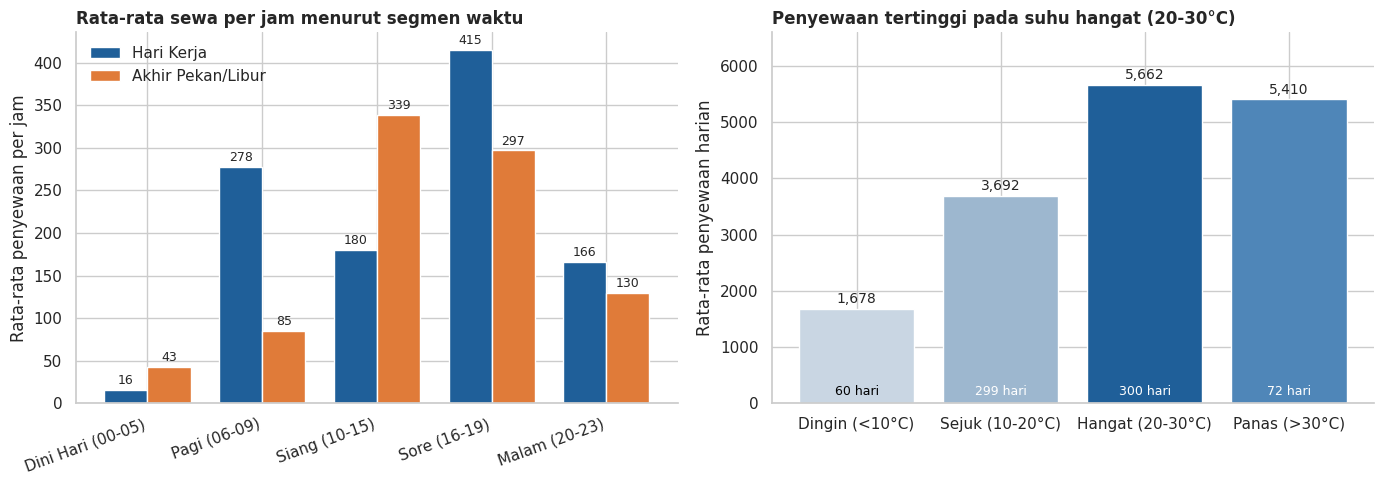

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))


segmen_plot = segmen[["Hari Kerja", "Akhir Pekan/Libur"]]
segmen_plot.plot(kind="bar", ax=axes[0], color=["#1f5f99", "#e07b39"], width=0.75)
axes[0].set_title("Rata-rata sewa per jam menurut segmen waktu", fontsize=12, fontweight="bold", loc="left")
axes[0].set_xlabel("")
axes[0].set_ylabel("Rata-rata penyewaan per jam")
axes[0].set_xticklabels([s.get_text()[3:] for s in axes[0].get_xticklabels()], rotation=20, ha="right")
axes[0].legend(frameon=False)
for wadah in axes[0].containers:
    axes[0].bar_label(wadah, fmt="%.0f", padding=2, fontsize=9)


warna_suhu = ["#c9d6e3", "#9db7cf", "#1f5f99", "#4f86b8"]
axes[1].bar(suhu.index.astype(str), suhu["rata_rata"], color=warna_suhu)
for i, (nilai, n) in enumerate(zip(suhu["rata_rata"], suhu["jumlah_hari"])):
    axes[1].text(i, nilai + 100, f"{nilai:,.0f}", ha="center", fontsize=10)
    axes[1].text(i, 150, f"{int(n)} hari", ha="center", fontsize=9, color="white" if nilai > 3000 else "black")
axes[1].set_title("Penyewaan tertinggi pada suhu hangat (20-30°C)", fontsize=12, fontweight="bold", loc="left")
axes[1].set_ylabel("Rata-rata penyewaan harian")
axes[1].set_ylim(0, 6600)
plt.tight_layout()
plt.show()

**Insight:**
- Pada hari kerja, segmen **Sore (±415 sewa/jam)** dan **Pagi (±278)** adalah yang tersibuk, sedangkan **Dini Hari** hanya ±16 sewa/jam (sekitar 2% dari total sewa hari kerja), sehingga cocok sebagai jendela perawatan dan pengisian ulang/redistribusi sepeda.
- Porsi pengguna *casual* jauh lebih besar pada akhir pekan/libur (±32%) daripada hari kerja (±13%), dan paling tinggi pada segmen Siang (±29%), menunjukkan peluang promosi wisata/rekreasi pada akhir pekan siang hari.
- Penyewaan harian naik tajam dari kisaran suhu <10°C (±1.678) ke 20-30°C (±5.662), lalu sedikit turun pada suhu >30°C (±5.410).
- Pada kelompok tingkat permintaan, Spring didominasi hari berpermintaan Rendah, sedangkan Summer dan Fall paling banyak memiliki hari berpermintaan Tinggi/Sangat Tinggi.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Pola penyewaan per jam berbeda jelas antara hari kerja dan akhir pekan/libur selama 2011-2012. Hari kerja memiliki dua puncak komuter, yaitu pagi sekitar 08.00 (±477 sewa/jam) dan sore 17.00-18.00 (±525 dan ±492 sewa/jam); pukul 07-09 dan 16-19 menyumbang sekitar 58% sewa hari kerja. Akhir pekan/libur hanya punya satu puncak landai sekitar 13.00 (±373 sewa/jam) dengan sekitar 49% sewa terkonsentrasi pukul 11-16. Selisih terbesar ada pada pukul 08.00, rata-rata sewa hari kerja sekitar 4,5 kali akhir pekan (±477 vs ±106).
- **Conclusion pertanyaan 2:** Rata-rata penyewaan harian berkaitan erat dengan musim dan cuaca: tertinggi ada pada Fall (±5.644) dan terendah pada Spring (±2.604). Dibanding hari cerah (±4.877), hari berkabut/berawan turun ±17% dan hari hujan/salju ringan turun ±63%. Dari 2011 ke 2012, rata-rata penyewaan harian tumbuh ±64% (±3.406 menjadi ±5.600) dan seluruh musim ikut naik. Catatan: hari hujan/salju ringan hanya 21 hari sehingga estimasinya kurang stabil.

**Rekomendasi Action Item:**
- **Redistribusi sepeda mengikuti jam komuter:** pada hari kerja, pastikan stok sepeda penuh di stasiun area permukiman sebelum 07.00 dan di stasiun area perkantoran sebelum 16.00; gunakan pukul 00.00-05.00 hari kerja (±16 sewa/jam) dan siang hari kerja 10.00-15.00 (±180 sewa/jam, jauh di bawah jam sibuk) sebagai jendela perawatan dan pengisian ulang armada.
- **Siapkan armada akhir pekan di area rekreasi:** akhir pekan/libur ramai pukul 11.00-16.00 dengan porsi pengguna *casual* yang lebih tinggi (±32%), sehingga stok di area wisata perlu ditambah dan paket promosi wisata/harian dapat difokuskan pada jam tersebut.
- **Jadwalkan promosi dan perawatan menurut musim:** tempatkan perawatan besar armada pada Spring/awal tahun saat permintaan terendah, dan fokuskan kampanye pemasaran (misalnya promo atau program loyalitas untuk membangun kebiasaan) di Spring dan Winter agar permintaan lebih merata, serta siapkan kapasitas maksimal pada Summer-Fall.
- **Antisipasi cuaca buruk:** terapkan penyesuaian operasional (misalnya mengurangi sepeda yang disebar dan menunda perawatan di hari prakiraan hujan/salju, menyediakan promo hari cerah setelah cuaca buruk) karena permintaan turun hingga ±63% pada hari hujan/salju ringan.
- **Pantau pertumbuhan:** karena penyewaan tumbuh ±64% pada 2012, evaluasi kapasitas armada dan stasiun secara berkala agar ketersediaan sepeda pada jam puncak tetap terjaga.